# 2. Precision versus Gμ: SBI scans and Fisher forecasts

How the precision curves of the paper (Fig. 3, Table II) are produced:

* **SBI scan**: for each injected Gμ, simulate several noise realisations, sample the posterior, and average the 95% HDI precision.
* **Fisher forecast**: Gaussian approximation of the likelihood at the injected point, classic or with the Gaussian foreground priors.

The paper uses 33 injections × 20 realisations × 10 000 samples (hours). Here a small version runs in a few minutes.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from gwbf_foregrounds import scan, fisher, stats, summary
from gwbf_foregrounds.plotting import precision as P

## A small SBI scan

`run_sbi_scan` saves one file per injection and a summary file with the same format as the paper's results.

In [2]:
grid = np.array([-15.0, -13.0, -11.0])
summ = scan.run_sbi_scan("full", logGmu_values=grid, n_datasets=3, n_samples=2000,
                         output_dir="scan_demo", summary_name="demo_full")

[demo_full] logGmu=-15.00  precision = 222 +- 32.1 %


[demo_full] logGmu=-13.00  precision = 45.7 +- 3.1 %


[demo_full] logGmu=-11.00  precision = 11.6 +- 1.51 %
Summary saved -> scan_demo/demo_full_summary_with_errors.npz


In [3]:
for lg, p, e in zip(summ["logGmu_inj"], summ["precision_mean"], summ["precision_std"]):
    print(f"Gmu = 1e{lg:.0f}:  precision = {p:.1f} +- {e:.1f} %")

Gmu = 1e-15:  precision = 222.1 +- 32.1 %
Gmu = 1e-13:  precision = 45.7 +- 3.1 %
Gmu = 1e-11:  precision = 11.6 +- 1.5 %


Low and high foregrounds: `fg_sign=-1` / `+1`. Other models: `"nofg"`, `"gbexb"`. The full paper grid is the default:

```python
scan.run_sbi_scan("full")                       # 33 injections, 20 realisations: hours
scan.run_sbi_scan("full", fg_sign=+1)           # foregrounds at fiducial +1 sigma
```
or from the command line: `gwbf-fg scan --model full`.

## Fisher forecasts

Classic Fisher (likelihood only) and Fisher with the Gaussian foreground priors (the same prior information SBI and MCMC use):

In [4]:
fis_classic = fisher.run_fisher("full", logGmu_values=grid, output_dir="scan_demo", verbose=False)
fis_priors = fisher.run_fisher("full", logGmu_values=grid, output_dir="scan_demo", with_priors=True, verbose=False)
for lg, a, b, c in zip(grid, summ["precision_mean"], fis_classic["precision"], fis_priors["precision"]):
    print(f"Gmu = 1e{lg:.0f}:  SBI {a:7.1f} %   Fisher {b:7.1f} %   Fisher + priors {c:7.1f} %")

Gmu = 1e-15:  SBI   222.1 %   Fisher   223.6 %   Fisher + priors   206.1 %
Gmu = 1e-13:  SBI    45.7 %   Fisher    58.9 %   Fisher + priors    55.4 %
Gmu = 1e-11:  SBI    11.6 %   Fisher    13.5 %   Fisher + priors    11.4 %


The Fisher matrix itself, e.g. to look at correlations:

In [5]:
from gwbf_foregrounds import FULL
F = fisher.fisher_matrix(FULL, FULL.fiducial(logGmu=-12), with_priors=True)
C = np.linalg.inv(F)
corr = C / np.sqrt(np.outer(np.diag(C), np.diag(C)))
print("correlation of log10 Gmu with:", dict(zip(FULL.param_names[1:], np.round(corr[0, 1:], 2))))

correlation of log10 Gmu with: {'A_p': 0.33, 'A_acc': -0.47, 'logA_Gal': -0.74, 'logA_ExB': 0.41, 'logA_ExWB': 0.4, 'logA_EMRI': -0.95}


## Plotting

The same plot functions as for the paper figures, here with the small scan:

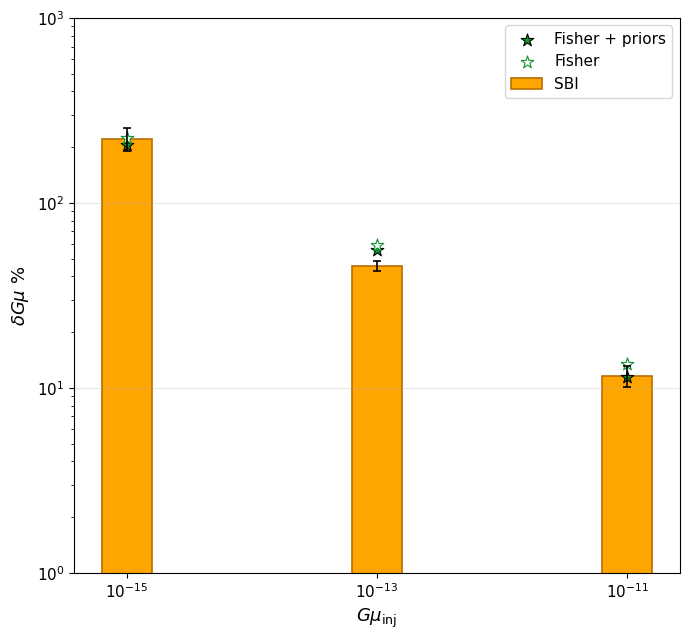

In [6]:
P.plot_paper_fig4(summ, fisher={"Fisher + priors": fis_priors, "Fisher": fis_classic}, ylim=(1, 1e3));

With the full results of the paper (in `results/`):

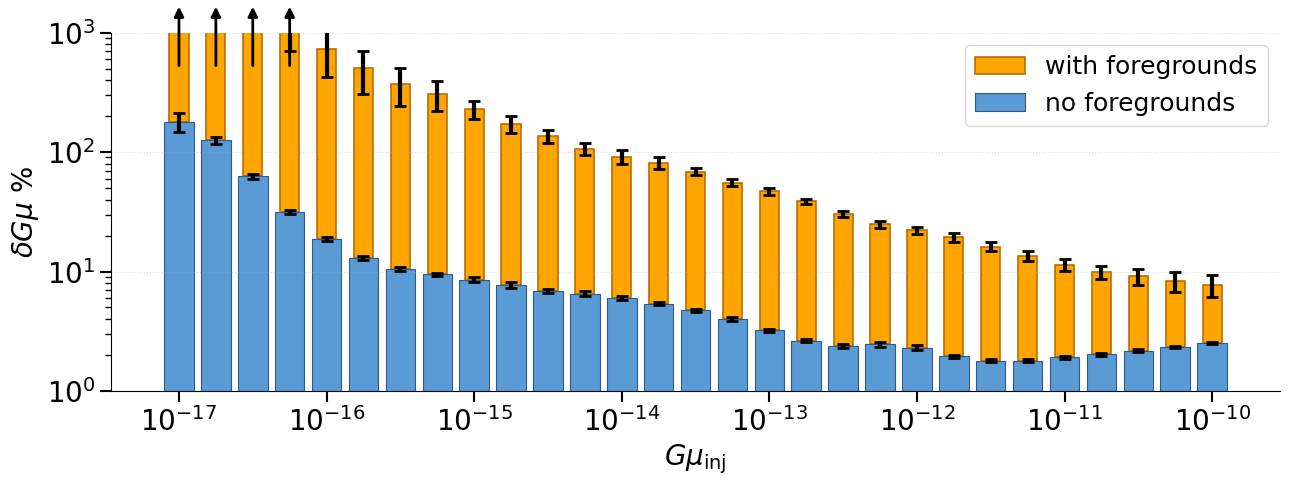

In [7]:
R = "../results/"
P.plot_fg_vs_nofg(R + "sbi_fg_summary_with_errors.npz", R + "sbi_nofg_summary_with_errors.npz");

In [8]:
summary.print_report({"no fg": R + "sbi_nofg_summary_with_errors.npz",
                      "WD+SOBHB": R + "sbi_gbexb_summary_with_errors.npz",
                      "all fg": R + "sbi_fg_summary_with_errors.npz"})

Precision (%) at selected log10 G mu
  logGmu        no fg     WD+SOBHB       all fg
   -17.0        178.4        503.1         6105
   -15.0        8.561        50.54        229.5
   -12.0        2.302        7.181        22.06
   -11.0        1.908        4.985        11.36
   -10.0        2.525        3.768        7.717
    -9.0        2.878        2.831        6.704

log10 G mu where the precision crosses 100% and 10%
  no fg         100%  -16.668  (G mu = 2.146e-17)
  no fg          10%  -15.375  (G mu = 4.220e-16)
  WD+SOBHB      100%  -16.020  (G mu = 9.549e-17)
  WD+SOBHB       10%  -12.768  (G mu = 1.706e-13)
  all fg        100%  -14.144  (G mu = 7.173e-15)
  all fg         10%  -10.764  (G mu = 1.724e-11)


In [9]:
import shutil; shutil.rmtree("scan_demo")